<a href="https://colab.research.google.com/github/LakinduSachin/CR-CM-Coursework/blob/main/CR_%26_CM_Course_work_Draft2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Setup

The notebook uses the libraries below. The version cell records the exact versions available in the run environment so the analysis can be reproduced later.

In [1]:
# Install the packages used in this notebook (Google Colab)
%pip -q install yfinance scikit-learn scipy matplotlib seaborn openpyxl

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math
import warnings
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

versions = {}
for package in ["pandas", "numpy", "yfinance", "scikit-learn", "scipy", "matplotlib", "seaborn"]:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = "not found"

print("Package versions:")
for package, version in versions.items():
    print(f"{package}: {version}")

Package versions:
pandas: 2.2.3
numpy: 2.4.6
yfinance: 0.2.66
scikit-learn: 1.6.1
scipy: 1.16.3
matplotlib: 3.10.0
seaborn: 0.13.2


## 2. Dates, sources, and ticker snapshot

The current constituent list is retrieved from Wikipedia on the run date. Yahoo Finance is used for historical prices. A current constituent list is not a historical S&P 500 membership file, so results can have survivorship bias. The saved ticker snapshot makes the exact analysed universe visible.

In [3]:
STUDY_START = pd.Timestamp("2021-01-01")
STUDY_END = pd.Timestamp("2025-01-01")       # exclusive, as required by the brief
DOWNLOAD_START = pd.Timestamp("2020-11-01")   # warm-up so the first study sessions can use a 20-session volume baseline
BENCHMARK = "^GSPC"
MIN_DAILY_COVERAGE = 0.80
MIN_WEEKLY_COVERAGE = 0.80
MIN_PAIRED_WEEKS = 52
RANDOM_SEED = 42
OUTPUT_DIR = Path("coursework_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

retrieved_at_utc = datetime.now(timezone.utc).isoformat(timespec="seconds")
wiki_url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Keep the source table as well as the Yahoo-compatible symbols.
tables = pd.read_html(wiki_url, storage_options={"User-Agent": "Mozilla/5.0 coursework research"})
sp500 = tables[0].copy()
sp500["Symbol"] = sp500["Symbol"].astype(str).str.strip()
sp500["YahooSymbol"] = sp500["Symbol"].str.replace(".", "-", regex=False)
sp500 = sp500.drop_duplicates("YahooSymbol").reset_index(drop=True)
sp500.to_csv(OUTPUT_DIR / "ticker_universe_snapshot.csv", index=False)

print(f"Ticker list retrieved: {retrieved_at_utc}")
print(f"Companies / share classes in snapshot: {len(sp500)}")
display(sp500[[c for c in ["Symbol", "YahooSymbol", "Security", "GICS Sector", "GICS Sub-Industry"] if c in sp500.columns]].head(10))

Ticker list retrieved: 2026-11-22T06:37:10+00:00
Companies / share classes in snapshot: 503


,Symbol,YahooSymbol,Security,GICS Sector,GICS Sub-Industry
0,MMM,MMM,3M,Industrials,Industrial Conglomerates
1,AOS,AOS,A. O. Smith,Industrials,Building Products
2,ABT,ABT,Abbott Laboratories,Health Care,Health Care Equipment
3,ABBV,ABBV,AbbVie,Health Care,Biotechnology
4,ACN,ACN,Accenture,Information Technology,IT Consulting & Other Services
5,ADBE,ADBE,Adobe Inc.,Information Technology,Application Software
6,AMD,AMD,Advanced Micro Devices,Information Technology,Semiconductors
7,AES,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders
8,AFL,AFL,Aflac,Financials,Life & Health Insurance
9,A,A,Agilent Technologies,Health Care,Life Sciences Tools & Services


## 3. Download and preserve daily data

The Yahoo request includes the required period and a short pre-period warm-up for the rolling volume baseline. The coursework calculations are restricted to 1 January 2021–31 December 2024. `auto_adjust=False` keeps both `Close` and `Adj Close`: adjusted close is used for returns; close multiplied by volume is used for the requested approximate traded value.

The batch approach reduces the chance of one very large request failing. Missing downloads remain missing and are recorded; no missing price is filled.

In [4]:
symbols = sp500["YahooSymbol"].tolist() + [BENCHMARK]

# Download in batches so an intermittent failure is easier to identify and retry.
def download_in_batches(symbol_list, start, end, batch_size=60):
    blocks = []
    for start_ix in range(0, len(symbol_list), batch_size):
        batch = symbol_list[start_ix:start_ix + batch_size]
        print(f"Downloading symbols {start_ix + 1}–{start_ix + len(batch)} of {len(symbol_list)}")
        block = yf.download(
            batch,
            start=start.strftime("%Y-%m-%d"),
            end=end.strftime("%Y-%m-%d"),
            auto_adjust=False,
            actions=True,
            progress=False,
            group_by="column",
            threads=True,
        )
        if block is not None and not block.empty:
            blocks.append(block)
    if not blocks:
        raise RuntimeError("Yahoo Finance returned no price data. Retry later or use a documented cached stock dataset.")
    return pd.concat(blocks, axis=1).sort_index(axis=1)

raw_download = download_in_batches(symbols, DOWNLOAD_START, STUDY_END)
print("Raw download shape:", raw_download.shape)
print("Column layout:", type(raw_download.columns).__name__)
raw_download.head()

ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['HONA', 'FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2020-11-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1604203200, endDate = 1735707600")')


ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['SNDK', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2020-11-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1604203200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2020-11-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1604203200, endDate = 1735707600")')


Raw download shape: (1047, 4022)
Column layout: MultiIndex


Price        Adj Close                                                                                                                                       \
Ticker               A        AAPL       ABBV ABNB         ABT       ACGL         ACN        ADBE         ADI        ADM         ADP        ADSK        AEE   
Date                                                                                                                                                          
2020-11-02  100.966583  105.333084  70.508873  NaN   95.816574  29.829687  199.214478  444.940002  107.135109  40.786400  141.590698  240.740005  69.913605   
2020-11-03  102.683891  106.950310  70.277161  NaN   97.670868  30.343172  204.208618  454.019989  108.283493  40.232052  145.992920  248.309998  70.846222   
2020-11-04  104.084618  111.317795  75.502411  NaN   99.427078  30.409735  206.208099  487.230011  113.880783  39.064564  144.326736  245.889999  70.115242   
2020-11-05  105.859474  115.268883  74.855247  NaN  101.210060  30.343172  211.699860  496.470001  117.913712  40.240452  142.686859  255.919998  69.291862   
2020-11-06  107.970154  115.137932  74.184113  NaN  102.003464  30.000849  213.780762  494.630005  120.716911  40.542824  145.773697  259.410004  68.770920   

Price                                                                                                                                                \
Ticker            AEP        AES        AFL        AIG         AIZ         AJG        AKAM         ALB        ALGN        ALL       ALLE       AMAT   
Date                                                                                                                                                  
2020-11-02  73.101044  15.860763  30.784746  28.176323  117.320236   99.717888   95.809998   90.265823  458.440002  78.814873  93.749954  57.312912   
2020-11-03  72.828598  16.074881  31.408773  28.558378  114.051575  101.084511   95.669998   90.992867  465.010010  80.566345  96.123497  58.737888   
2020-11-04  72.235657  15.813182  31.660112  27.429585  113.672340  104.604080   99.339996   87.087341  483.459991  79.803314  93.786926  61.616364   
2020-11-05  72.684349  16.630001  32.240788  29.027260  114.999649  102.750664  102.709999   98.337944  491.910004  78.390045  96.169655  66.451797   
2020-11-06  72.852623  16.185904  31.980791  28.792820  114.755875  103.443390  101.629997  104.601746  477.850006  79.031654  94.969055  67.002823   

Price                                                                                                                                                 \
Ticker           AMCR        AMD         AME        AMGN         AMP         AMT        AMZN       ANET         AON        AOS       APA         APD   
Date                                                                                                                                                   
2020-11-02  40.595795  74.699997   98.390320  182.064224  149.425735  194.529037  150.223999  13.507500  172.730453  47.211826  7.569660  247.283447   
2020-11-03  41.680851  76.580002  101.295776  181.940216  152.151672  195.145569  152.420502  15.593125  172.080231  47.613815  7.433422  249.310486   
2020-11-04  41.493755  81.349998  101.391975  190.431213  153.014832  197.511642  162.057999  15.902500  175.446060  46.827705  7.654809  249.526016   
2020-11-05  43.065205  83.000000  104.913155  191.787125  156.912933  199.886063  166.100006  16.062500  177.262924  48.078339  7.637779  261.644928   
2020-11-06  43.102627  85.879997  106.134941  191.539078  155.203491  201.743988  165.568497  16.437500  182.015305  48.739410  7.271641  264.560333   

Price                                                                                                                                                      \
Ticker            APH        APO APP        APTV         ARE       ARES        ATO       AVGO         AVY         AWK        AXON        AXP    

In [5]:
# yfinance has returned both two-level column layouts over time; this helper handles either one.
def extract_field(frame, field):
    if isinstance(frame.columns, pd.MultiIndex):
        for level in range(frame.columns.nlevels):
            if field in frame.columns.get_level_values(level):
                result = frame.xs(field, axis=1, level=level, drop_level=True)
                if isinstance(result, pd.Series):
                    result = result.to_frame()
                return result
        return pd.DataFrame(index=frame.index)
    if field in frame.columns:
        return frame[[field]].copy()
    return pd.DataFrame(index=frame.index)

# A duplicate date is a data-quality problem. If the provider returns one, retain the last row and record it.
duplicate_date_count = int(raw_download.index.duplicated(keep="last").sum())
raw_download = raw_download.loc[~raw_download.index.duplicated(keep="last")].copy()
raw_download.index = pd.DatetimeIndex(pd.to_datetime(raw_download.index)).tz_localize(None)
raw_download = raw_download.sort_index()

field_names = ["Adj Close", "Close", "Volume", "Dividends", "Stock Splits"]
fields = {name: extract_field(raw_download, name) for name in field_names}
for name, frame in fields.items():
    frame.columns = frame.columns.astype(str)
    fields[name] = frame.reindex(columns=symbols)

adj_close = fields["Adj Close"]
close = fields["Close"]
volume = fields["Volume"]
dividends = fields["Dividends"].fillna(0)
splits = fields["Stock Splits"].fillna(0)

# Save a long, compressed snapshot so the run can be checked without relying on a later live download.
parts = []
for field_name, frame in fields.items():
    long = frame.rename_axis(index="Date", columns="Ticker").stack(dropna=False).rename(field_name).reset_index()
    parts.append(long)
daily_snapshot = parts[0]
for part in parts[1:]:
    daily_snapshot = daily_snapshot.merge(part, on=["Date", "Ticker"], how="outer")
daily_snapshot.to_csv(OUTPUT_DIR / "daily_prices_snapshot.csv.gz", index=False, compression="gzip")

print("Duplicate dates removed:", duplicate_date_count)
print("Daily snapshot rows:", len(daily_snapshot))
daily_snapshot.head()

Duplicate dates removed: 0
Daily snapshot rows: 527688


,Date,Ticker,Adj Close,Close,Volume,Dividends,Stock Splits
0,2020-11-02,A,100.966583,105.239998,1572300.0,0.0,0.0
1,2020-11-02,AAPL,105.333084,108.769997,122866900.0,0.0,0.0
2,2020-11-02,ABBV,70.508873,88.250000,10781400.0,0.0,0.0
3,2020-11-02,ABNB,NaN,NaN,NaN,NaN,NaN
4,2020-11-02,ABT,95.816574,107.480003,5907100.0,0.0,0.0


## 4. Validation, coverage, and exclusions

The brief does not prescribe a numeric minimum for unequal histories. This notebook uses an explicit 80% coverage screen against benchmark trading sessions and a minimum of 52 aligned weekly observations. These are operational screening choices, not rules stated by the brief; report them and explain their effect. Values are never filled. The inclusion log also records nonpositive prices, invalid volume, first/last observations, coverage, and corporate-action counts.

In [6]:
# Restrict the validation frame to the study window, the warm-up remains available for volume thresholds.
study_dates = raw_download.index[(raw_download.index >= STUDY_START) & (raw_download.index < STUDY_END)]
benchmark_prices = adj_close.get(BENCHMARK, pd.Series(dtype=float)).loc[study_dates]
benchmark_sessions = benchmark_prices.index[benchmark_prices.notna() & benchmark_prices.gt(0)]
if len(benchmark_sessions) == 0:
    raise RuntimeError("The benchmark has no valid adjusted prices in the study period.")

metadata_by_yahoo = sp500.set_index("YahooSymbol")
validation_rows = []
valid_daily_by_ticker = {}
for ticker in sp500["YahooSymbol"]:
    adj = adj_close[ticker].reindex(benchmark_sessions)
    raw_close = close[ticker].reindex(benchmark_sessions)
    vol = volume[ticker].reindex(benchmark_sessions)
    valid = adj.notna() & raw_close.notna() & vol.notna() & adj.gt(0) & raw_close.gt(0) & vol.ge(0)
    valid_daily_by_ticker[ticker] = valid
    valid_dates = valid.index[valid]
    n_valid = int(valid.sum())
    coverage = n_valid / len(benchmark_sessions)
    first_date = valid_dates.min() if n_valid else pd.NaT
    last_date = valid_dates.max() if n_valid else pd.NaT
    nonpositive_adj = int((adj.notna() & adj.le(0)).sum())
    nonpositive_close = int((raw_close.notna() & raw_close.le(0)).sum())
    negative_volume = int((vol.notna() & vol.lt(0)).sum())
    missing_required = int((~valid).sum())
    split_count = int((splits[ticker].reindex(benchmark_sessions).fillna(0) != 0).sum())
    dividend_count = int((dividends[ticker].reindex(benchmark_sessions).fillna(0) != 0).sum())
    reasons = []
    if n_valid == 0:
        reasons.append("no valid price/volume observations")
    if coverage < MIN_DAILY_COVERAGE:
        reasons.append(f"daily coverage below {MIN_DAILY_COVERAGE:.0%}")
    if n_valid < 60:
        reasons.append("fewer than 60 valid study sessions")
    validation_rows.append({
        "YahooSymbol": ticker,
        "Symbol": metadata_by_yahoo.loc[ticker, "Symbol"],
        "Security": metadata_by_yahoo.loc[ticker, "Security"],
        "Sector": metadata_by_yahoo.loc[ticker, "GICS Sector"] if "GICS Sector" in metadata_by_yahoo.columns else "Unknown",
        "Expected_Benchmark_Sessions": len(benchmark_sessions),
        "Valid_Sessions": n_valid,
        "Daily_Coverage": coverage,
        "Missing_or_Invalid_Sessions": missing_required,
        "Nonpositive_AdjClose": nonpositive_adj,
        "Nonpositive_Close": nonpositive_close,
        "Negative_Volume": negative_volume,
        "First_Valid_Date": first_date,
        "Last_Valid_Date": last_date,
        "Split_Action_Days": split_count,
        "Dividend_Action_Days": dividend_count,
        "Daily_Screen_Reason": "; ".join(reasons) if reasons else "included in daily screen",
    })

validation = pd.DataFrame(validation_rows).set_index("YahooSymbol")
display(validation["Daily_Coverage"].describe().to_frame("Daily_Coverage"))
display(validation.sort_values("Daily_Coverage").head(12))

,Daily_Coverage
count,503.000000
mean,0.981779
std,0.123011
min,0.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000


,Symbol,Security,Sector,Expected_Benchmark_Sessions,Valid_Sessions,Daily_Coverage,Missing_or_Invalid_Sessions,Nonpositive_AdjClose,Nonpositive_Close,Negative_Volume,First_Valid_Date,Last_Valid_Date,Split_Action_Days,Dividend_Action_Days,Daily_Screen_Reason
YahooSymbol,,,,,,,,,,,,,,,
VYLR,VYLR,Vylor,Consumer Staples,1005,0,0.000000,1005,0,0,0,NaT,NaT,0,0,no valid price/volume observations; daily cove...
SNDK,SNDK,Sandisk,Information Technology,1005,0,0.000000,1005,0,0,0,NaT,NaT,0,0,no valid price/volume observations; daily cove...
Q,Q,Qnity Electronics,Information Technology,1005,0,0.000000,1005,0,0,0,NaT,NaT,0,0,no valid price/volume observations; daily cove...
HONA,HONA,Honeywell Aerospace,Industrials,1005,0,0.000000,1005,0,0,0,NaT,NaT,0,0,no valid price/volume observations; daily cove...
FDXF,FDXF,FedEx Freight,Industrials,1005,0,0.000000,1005,0,0,0,NaT,NaT,0,0,no valid price/volume observations; daily cove...
GEV,GEV,GE Vernova,Industrials,1005,193,0.192040,812,0,0,0,2024-03-27,2024-12-31,0,1,daily coverage below 80%
SOLV,SOLV,Solventum,Health Care,1005,194,0.193035,811,0,0,0,2024-03-26,2024-12-31,0,0,daily coverage below 80%
RDDT,RDDT,Reddit,Communication Services,1005,197,0.196020,808,0,0,0,2024-03-21,2024-12-31,0,0,daily coverage below 80%
VLTO,VLTO,Veralto,Industrials,1005,313,0.311443,692,0,0,0,2023-10-04,2024-12-31,0,5,daily coverage below 80%


## 5. Weekly adjusted-price returns and beta

Weekly prices use the last available adjusted close in each Friday-ending week. Only full Monday–Friday calendar weeks whose Monday and Friday labels fall inside the study period are retained. Empty weekly bins stay missing; `pct_change(fill_method=None)` does not bridge a missing week. The mean return and beta use the same share/benchmark paired weekly observations. Beta is covariance divided by benchmark variance, using the full study period.

In [7]:
weekly_prices_all = adj_close.resample("W-FRI").last()
all_week_labels = weekly_prices_all.index
# A full study week must start on/after the study start and end before the exclusive end date.
full_week_labels = all_week_labels[
    (all_week_labels - pd.Timedelta(days=4) >= STUDY_START) &
    (all_week_labels < STUDY_END)
]
weekly_prices = weekly_prices_all.reindex(full_week_labels)
weekly_returns_all = weekly_prices.pct_change(fill_method=None)
market_weekly = weekly_returns_all[BENCHMARK]
valid_market_returns = market_weekly.dropna()
expected_return_weeks = len(valid_market_returns)

risk_rows = []
for ticker in sp500["YahooSymbol"]:
    if ticker not in weekly_returns_all.columns:
        continue
    paired = pd.concat(
        [weekly_returns_all[ticker].rename("share_return"), market_weekly.rename("market_return")],
        axis=1,
    ).replace([np.inf, -np.inf], np.nan).dropna()
    n_pair = len(paired)
    market_variance = paired["market_return"].var(ddof=1) if n_pair >= 2 else np.nan
    beta_value = paired["share_return"].cov(paired["market_return"]) / market_variance if n_pair >= 2 and market_variance > 0 else np.nan
    mean_return = paired["share_return"].mean() if n_pair else np.nan
    coverage = n_pair / expected_return_weeks if expected_return_weeks else np.nan
    risk_rows.append({
        "YahooSymbol": ticker,
        "Mean_Weekly_Return": mean_return,
        "Weekly_Beta": beta_value,
        "Paired_Weekly_Observations": n_pair,
        "Weekly_Coverage": coverage,
    })

risk_features_all = pd.DataFrame(risk_rows).set_index("YahooSymbol")
risk_features_all = risk_features_all.join(validation[["Daily_Coverage", "Sector", "Symbol", "Security"]])
risk_features_all["Risk_Screen_Reason"] = np.where(
    (risk_features_all["Weekly_Coverage"] >= MIN_WEEKLY_COVERAGE) &
    (risk_features_all["Paired_Weekly_Observations"] >= MIN_PAIRED_WEEKS) &
    risk_features_all[["Mean_Weekly_Return", "Weekly_Beta"]].notna().all(axis=1),
    "included in risk screen",
    "weekly coverage/count or feature check failed",
)

risk_eligible = risk_features_all.loc[
    risk_features_all["Daily_Coverage"].ge(MIN_DAILY_COVERAGE) &
    risk_features_all["Weekly_Coverage"].ge(MIN_WEEKLY_COVERAGE) &
    risk_features_all["Paired_Weekly_Observations"].ge(MIN_PAIRED_WEEKS) &
    risk_features_all[["Mean_Weekly_Return", "Weekly_Beta"]].notna().all(axis=1)
].copy()

print("Complete weekly labels:", len(full_week_labels))
print("Benchmark return observations:", expected_return_weeks)
print("Shares passing weekly and daily screens:", len(risk_eligible))
display(risk_eligible[["Mean_Weekly_Return", "Weekly_Beta", "Paired_Weekly_Observations", "Weekly_Coverage"]].describe().T)
display(risk_features_all["Risk_Screen_Reason"].value_counts().to_frame("Shares"))

Complete weekly labels: 208
Benchmark return observations: 207
Shares passing weekly and daily screens: 492


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,492.0,0.002900,0.002697,-0.004468,0.001204,0.002668,0.004264,0.017772
Weekly_Beta,492.0,0.982446,0.422073,0.055453,0.670048,0.954712,1.183847,3.778560
Paired_Weekly_Observations,492.0,206.873984,1.595683,178.000000,207.000000,207.000000,207.000000,207.000000
Weekly_Coverage,492.0,0.999391,0.007709,0.859903,1.000000,1.000000,1.000000,1.000000


,Shares
Risk_Screen_Reason,
included in risk screen,492
weekly coverage/count or feature check failed,11


## 6. Adapted daily RFM measures

- **Recency:** calendar days from the latest qualifying high-volume day in the study history to the final common observation date.
- **Frequency:** qualifying high-volume days in the latest 60 valid share sessions.
- **Monetary:** sum of `Close × Volume` over those same 60 sessions, in USD.

For each share and date, the threshold is twice the mean volume in the **preceding** 20 valid share sessions. The current session is excluded by shifting the rolling mean. A missing Recency event remains missing and that share is excluded from RFM clustering; zero is never substituted.

In [8]:
# Find the final date shared by the risk-screened shares with valid adjusted close, Close, and Volume.
common_candidates = risk_eligible.index.tolist()
if not common_candidates:
    raise RuntimeError("No shares passed the documented daily and weekly screens.")
valid_panel = pd.DataFrame({t: valid_daily_by_ticker[t] for t in common_candidates}, index=benchmark_sessions)
common_dates = valid_panel.index[valid_panel.all(axis=1)]
if len(common_dates) == 0:
    raise RuntimeError("No common daily observation date exists for the screened share set.")
OBSERVATION_DATE = common_dates.max()
print("Final common observation date:", OBSERVATION_DATE.date())

rfm_rows = []
rfm_details = {}
for ticker in common_candidates:
    # Includes only actual valid share sessions, the test data builds the initial rolling threshold.
    hist_index = raw_download.index[(raw_download.index >= DOWNLOAD_START) & (raw_download.index <= OBSERVATION_DATE)]
    hist = pd.DataFrame({
        "Close": close[ticker].reindex(hist_index),
        "Volume": volume[ticker].reindex(hist_index),
    })
    hist = hist.loc[hist["Close"].gt(0) & hist["Volume"].ge(0)].dropna().sort_index()
    hist["Prior20_Mean_Volume"] = hist["Volume"].shift(1).rolling(window=20, min_periods=20).mean()
    hist["Threshold_2x_Prior20"] = 2 * hist["Prior20_Mean_Volume"]
    hist["High_Volume_Event"] = hist["Volume"].gt(hist["Threshold_2x_Prior20"])

    study_hist = hist.loc[(hist.index >= STUDY_START) & (hist.index <= OBSERVATION_DATE)]
    events = study_hist.index[study_hist["High_Volume_Event"]]
    last60 = study_hist.tail(60)
    if len(last60) < 60:
        rfm_rows.append({"YahooSymbol": ticker, "R_Recency_Days": np.nan, "F_High_Volume_Days": np.nan,
                         "M_Traded_Value_USD": np.nan, "RFM_Screen_Reason": "fewer than 60 valid sessions"})
        rfm_details[ticker] = hist
        continue

    recency_days = (OBSERVATION_DATE - events.max()).days if len(events) else np.nan
    frequency = int(last60["High_Volume_Event"].sum())
    monetary = float((last60["Close"] * last60["Volume"]).sum())
    reason = "included in RFM screen" if np.isfinite(recency_days) else "no qualifying high-volume event; Recency missing"
    rfm_rows.append({
        "YahooSymbol": ticker,
        "R_Recency_Days": recency_days,
        "F_High_Volume_Days": frequency,
        "M_Traded_Value_USD": monetary,
        "RFM_Screen_Reason": reason,
    })
    rfm_details[ticker] = hist

rfm_all = pd.DataFrame(rfm_rows).set_index("YahooSymbol")
print("RFM observation date:", OBSERVATION_DATE.date())
print("RFM eligible shares:", int(rfm_all[["R_Recency_Days", "F_High_Volume_Days", "M_Traded_Value_USD"]].notna().all(axis=1).sum()))
display(rfm_all["RFM_Screen_Reason"].value_counts().to_frame("Shares"))
display(rfm_all[["R_Recency_Days", "F_High_Volume_Days", "M_Traded_Value_USD"]].describe().T)

Final common observation date: 2024-12-31
RFM observation date: 2024-12-31
RFM eligible shares: 492


,Shares
RFM_Screen_Reason,
included in RFM screen,492


,count,mean,std,min,25%,50%,75%,max
R_Recency_Days,492.0,2.049390e+01,2.130398e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.800000e+01,2.220000e+02
F_High_Volume_Days,492.0,2.995935e+00,1.328055e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M_Traded_Value_USD,492.0,3.974218e+10,1.286397e+11,1.297483e+09,1.025241e+10,1.679667e+10,3.253548e+10,1.847697e+12


### 6.1 Worked example and feature meaning

The following cell prints one real row from this run, including the final 60-session monetary calculation and a qualifying event threshold. Use this output as your worked example in the report. Explain the share's values in plain language and state that these measures describe trading activity, not company value, profitability, or a buy/sell signal.

In [9]:
# Valid RFM row and show the inputs behind its calculated values.
rfm_valid_tickers = rfm_all.index[rfm_all[["R_Recency_Days", "F_High_Volume_Days", "M_Traded_Value_USD"]].notna().all(axis=1)]
if len(rfm_valid_tickers):
    example_ticker = rfm_valid_tickers[0]
    example_hist = rfm_details[example_ticker]
    example_study = example_hist.loc[(example_hist.index >= STUDY_START) & (example_hist.index <= OBSERVATION_DATE)]
    example_last60 = example_study.tail(60)
    example_events = example_study.loc[example_study["High_Volume_Event"]]
    print("Worked example:", metadata_by_yahoo.loc[example_ticker, "Symbol"], "(", example_ticker, ")")
    print("Observation date:", OBSERVATION_DATE.date())
    print("Valid sessions in window:", len(example_last60))
    print("R (calendar days since latest event):", rfm_all.loc[example_ticker, "R_Recency_Days"])
    print("F (event days among last 60):", rfm_all.loc[example_ticker, "F_High_Volume_Days"])
    print("M (sum of Close × Volume, USD):", f"${rfm_all.loc[example_ticker, 'M_Traded_Value_USD']:,.2f}")
    if len(example_events):
        event_date = example_events.index.max()
        event_row = example_events.loc[event_date]
        print("Latest event date:", event_date.date())
        print("Volume on event date:", f"{event_row['Volume']:,.0f}")
        print("2 × preceding 20-session mean:", f"{event_row['Threshold_2x_Prior20']:,.0f}")
    display(example_last60.tail(5))
else:
    print("No share has all three RFM values; inspect the data validation and event-threshold calculations.")

Worked example: MMM ( MMM )
Observation date: 2024-12-31
Valid sessions in window: 60
R (calendar days since latest event): 11
F (event days among last 60): 4
M (sum of Close × Volume, USD): $25,991,458,733.34
Latest event date: 2024-12-20
Volume on event date: 8,351,300
2 × preceding 20-session mean: 6,055,080


,Close,Volume,Prior20_Mean_Volume,Threshold_2x_Prior20,High_Volume_Event
Date,,,,,
2024-12-24,130.360001,803200,3268615.0,6537230.0,False
2024-12-26,131.179993,1484900,3055040.0,6110080.0,False
2024-12-27,130.179993,1842600,2975270.0,5950540.0,False
2024-12-30,129.130005,2154000,2938420.0,5876840.0,False
2024-12-31,129.089996,2220300,2965205.0,5930410.0,False


## 7. Common share set, diagnostics, and feature scaling

The four baseline solutions must use the same shares. The shared set is the intersection of valid risk/return features and complete RFM features. Monetary is transformed using `log1p`,all clustering inputs are then standardised separately for each matrix. Recency and Frequency are inspected for skew and outliers, but kept in their original units before standardisation in the main analysis; explain this choice and discuss whether extreme values may affect Euclidean distance. No observation is winsorised or removed solely for being extreme.

Common shares used in all four baseline solutions: 492
Excluded from RFM due to no event / insufficient history: 0


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,492.0,2.899643e-03,2.697481e-03,-4.468094e-03,1.203835e-03,2.667512e-03,4.264246e-03,1.777248e-02
Weekly_Beta,492.0,9.824455e-01,4.220726e-01,5.545267e-02,6.700481e-01,9.547121e-01,1.183847e+00,3.778560e+00
R_Recency_Days,492.0,2.049390e+01,2.130398e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.800000e+01,2.220000e+02
F_High_Volume_Days,492.0,2.995935e+00,1.328055e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M_Traded_Value_USD,492.0,3.974218e+10,1.286397e+11,1.297483e+09,1.025241e+10,1.679667e+10,3.253548e+10,1.847697e+12
Log1p_M,492.0,2.369017e+01,9.467858e-01,2.098369e+01,2.305078e+01,2.354443e+01,2.420559e+01,2.824496e+01


,mean,median,std,min,max,skew,IQR
Mean_Weekly_Return,2.899643e-03,2.667512e-03,2.697481e-03,-4.468094e-03,1.777248e-02,0.937234,3.060411e-03
Weekly_Beta,9.824455e-01,9.547121e-01,4.220726e-01,5.545267e-02,3.778560e+00,1.247269,5.137994e-01
R_Recency_Days,2.049390e+01,1.100000e+01,2.130398e+01,4.000000e+00,2.220000e+02,3.618971,7.000000e+00
F_High_Volume_Days,2.995935e+00,3.000000e+00,1.328055e+00,0.000000e+00,8.000000e+00,0.416061,2.000000e+00
M_Traded_Value_USD,3.974218e+10,1.679667e+10,1.286397e+11,1.297483e+09,1.847697e+12,11.672945,2.228307e+10
Log1p_M,2.369017e+01,2.354443e+01,9.467858e-01,2.098369e+01,2.824496e+01,1.070277,1.154815e+00


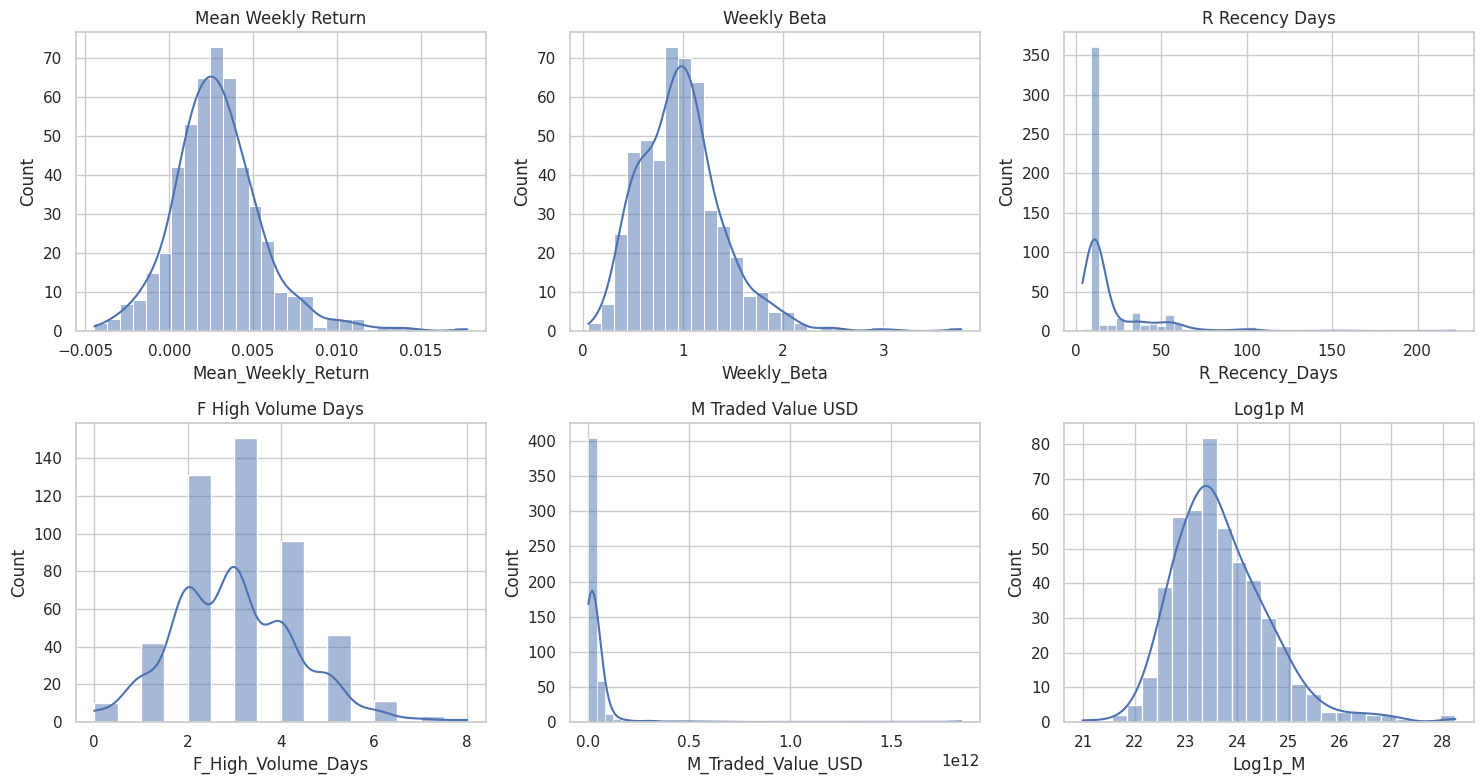

In [10]:
feature_table = risk_eligible.join(rfm_all, how="inner")
required_columns = ["Mean_Weekly_Return", "Weekly_Beta", "R_Recency_Days", "F_High_Volume_Days", "M_Traded_Value_USD"]
feature_table = feature_table.replace([np.inf, -np.inf], np.nan).dropna(subset=required_columns).copy()
feature_table["Log1p_M"] = np.log1p(feature_table["M_Traded_Value_USD"])
feature_table["Observation_Date"] = OBSERVATION_DATE
feature_table.index.name = "YahooSymbol"

print("Common shares used in all four baseline solutions:", len(feature_table))
print("Excluded from RFM due to no event / insufficient history:", int(len(risk_eligible) - len(feature_table)))
display(feature_table[required_columns + ["Log1p_M"]].describe().T)

feature_diagnostics = feature_table[["Mean_Weekly_Return", "Weekly_Beta", "R_Recency_Days", "F_High_Volume_Days", "M_Traded_Value_USD", "Log1p_M"]].agg(["mean", "median", "std", "min", "max", "skew"]).T
feature_diagnostics["IQR"] = feature_table[feature_diagnostics.index].quantile(.75) - feature_table[feature_diagnostics.index].quantile(.25)
display(feature_diagnostics)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ["Mean_Weekly_Return", "Weekly_Beta", "R_Recency_Days", "F_High_Volume_Days", "M_Traded_Value_USD", "Log1p_M"]):
    sns.histplot(feature_table[col], ax=ax, kde=True)
    ax.set_title(col.replace("_", " "))
plt.tight_layout()
plt.show()

In [11]:
risk_columns = ["Mean_Weekly_Return", "Weekly_Beta"]
rfm_columns = ["R_Recency_Days", "F_High_Volume_Days", "Log1p_M"]

risk_scaler = StandardScaler()
rfm_scaler = StandardScaler()
X_risk = pd.DataFrame(risk_scaler.fit_transform(feature_table[risk_columns]), index=feature_table.index, columns=risk_columns)
X_rfm = pd.DataFrame(rfm_scaler.fit_transform(feature_table[rfm_columns]), index=feature_table.index, columns=rfm_columns)

print("Risk/return scaled means:", X_risk.mean().round(3).to_dict())
print("Risk/return scaled standard deviations:", X_risk.std(ddof=0).round(3).to_dict())
print("RFM scaled means:", X_rfm.mean().round(3).to_dict())
print("RFM scaled standard deviations:", X_rfm.std(ddof=0).round(3).to_dict())

Risk/return scaled means: {'Mean_Weekly_Return': 0.0, 'Weekly_Beta': 0.0}
Risk/return scaled standard deviations: {'Mean_Weekly_Return': 1.0, 'Weekly_Beta': 1.0}
RFM scaled means: {'R_Recency_Days': 0.0, 'F_High_Volume_Days': -0.0, 'Log1p_M': -0.0}
RFM scaled standard deviations: {'R_Recency_Days': 1.0, 'F_High_Volume_Days': 1.0, 'Log1p_M': 1.0}


## 8. Ward agglomerative clustering

Ward linkage merges groups to minimise the increase in within-cluster variation and is used with Euclidean distance on standardised values. Its strengths are the visible hierarchy and a coherent variance-based rule; its limits include sensitivity to scaling/outliers, a preference for compact groups, and the need to choose a final cut. The dendrogram is supporting evidence, not an automatic cluster-count decision.

For each matrix, compare `k = 2…8` with silhouette, cluster sizes, and original-unit profiles. The notebook selects the highest-silhouette value as a starting candidate. Check the size and interpretability tables and the dendrogram before treating it as final; edit the selection cell if those checks support another `k`.

,Analysis,k,Silhouette,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk and return,2,0.508897,36,456,"456, 36"
1,Risk and return,3,0.262693,36,333,"333, 36, 123"
2,Risk and return,4,0.294582,36,177,"156, 36, 123, 177"
3,Risk and return,5,0.319414,36,177,"36, 111, 123, 177, 45"
4,Risk and return,6,0.324466,6,177,"111, 177, 123, 6, 45, 30"
5,Risk and return,7,0.306155,6,177,"177, 6, 123, 20, 45, 30, 91"
6,Risk and return,8,0.293995,6,123,"123, 6, 108, 20, 45, 30, 91, 69"


,Analysis,k,Silhouette,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,RFM activity,2,0.357788,93,399,"399, 93"
1,RFM activity,3,0.306805,93,252,"252, 93, 147"
2,RFM activity,4,0.292292,43,209,"93, 209, 147, 43"
3,RFM activity,5,0.311301,10,209,"147, 209, 10, 43, 83"
4,RFM activity,6,0.319504,10,209,"209, 127, 10, 43, 83, 20"
5,RFM activity,7,0.297803,10,143,"127, 83, 10, 43, 143, 20, 66"
6,RFM activity,8,0.303712,10,143,"10, 83, 70, 43, 143, 20, 66, 57"


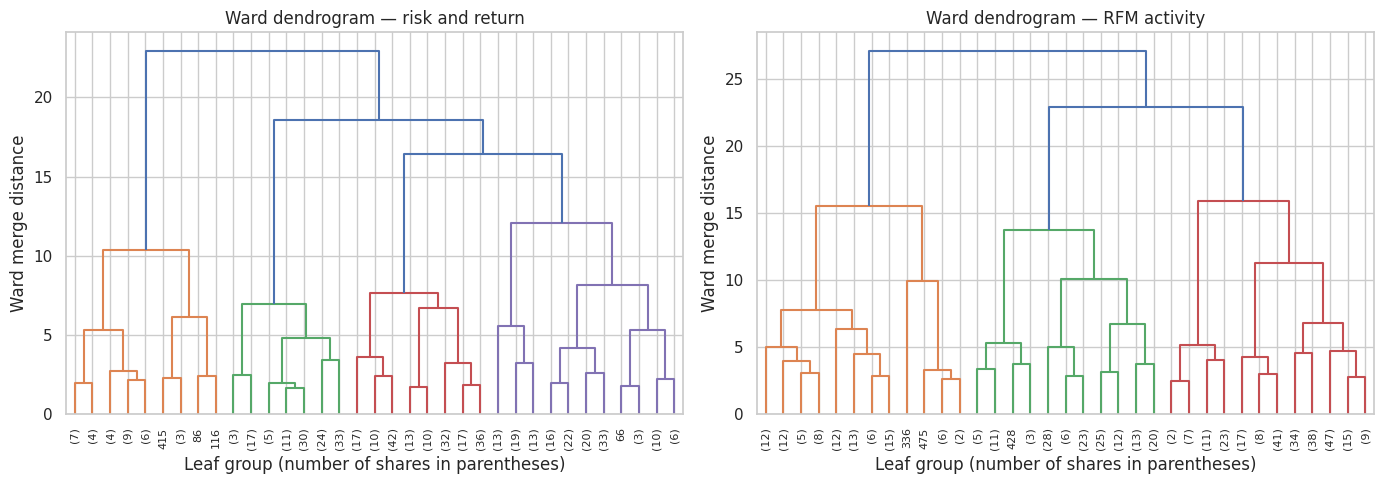

In [12]:
def evaluate_ward(X, name):
    rows = []
    labels_by_k = {}
    for k in range(2, 9):
        model = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean")
        labels = model.fit_predict(X)
        labels_by_k[k] = labels
        sizes = pd.Series(labels).value_counts().sort_index()
        rows.append({"Analysis": name, "k": k, "Silhouette": silhouette_score(X, labels),
                     "Smallest_Cluster": int(sizes.min()), "Largest_Cluster": int(sizes.max()),
                     "Cluster_Sizes": ", ".join(str(int(v)) for v in sizes.values)})
    return pd.DataFrame(rows), labels_by_k

ward_risk_scores, ward_risk_labels_by_k = evaluate_ward(X_risk, "Risk and return")
ward_rfm_scores, ward_rfm_labels_by_k = evaluate_ward(X_rfm, "RFM activity")
display(ward_risk_scores)
display(ward_rfm_scores)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, X, title in [(axes[0], X_risk, "Ward dendrogram — risk and return"), (axes[1], X_rfm, "Ward dendrogram — RFM activity")]:
    Z = linkage(X.to_numpy(), method="ward", metric="euclidean")
    dendrogram(Z, truncate_mode="lastp", p=35, show_leaf_counts=True, leaf_rotation=90, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Leaf group (number of shares in parentheses)")
    ax.set_ylabel("Ward merge distance")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ward_dendrograms.png", dpi=180, bbox_inches="tight")
plt.show()

### 8.1 Select and fit the two Ward solutions

The default uses the highest-silhouette candidate as a starting point. Review the tables above and set either value explicitly if a different count has a stronger combined case from silhouette, dendrogram structure, cluster sizes, and original-unit interpretability.

In [13]:
# Leave as None to start from the highest silhouette; replace with an integer 2–8 after reviewing the diagnostics.
SELECTED_K_WARD_RISK = None
SELECTED_K_WARD_RFM = None

def starting_k(score_table, manual_choice):
    if manual_choice is not None:
        if int(manual_choice) not in range(2, 9):
            raise ValueError("Selected k must be between 2 and 8.")
        return int(manual_choice)
    return int(score_table.sort_values("Silhouette", ascending=False).iloc[0]["k"])

k_ward_risk = starting_k(ward_risk_scores, SELECTED_K_WARD_RISK)
k_ward_rfm = starting_k(ward_rfm_scores, SELECTED_K_WARD_RFM)
ward_risk_model = AgglomerativeClustering(n_clusters=k_ward_risk, linkage="ward", metric="euclidean")
ward_rfm_model = AgglomerativeClustering(n_clusters=k_ward_rfm, linkage="ward", metric="euclidean")
ward_risk_labels = pd.Series(ward_risk_model.fit_predict(X_risk), index=feature_table.index, name="Ward_Risk_Cluster")
ward_rfm_labels = pd.Series(ward_rfm_model.fit_predict(X_rfm), index=feature_table.index, name="Ward_RFM_Cluster")
print("Starting Ward choices:", {"risk_return": k_ward_risk, "RFM": k_ward_rfm})

Starting Ward choices: {'risk_return': 2, 'RFM': 2}


## 9. K-means clustering

K-means assigns shares to the nearest centroid and minimises within-cluster squared distance. It is efficient and easy to profile, but works best for roughly compact, similarly scaled groups and can be influenced by outliers and starting centroids. A fixed random seed and 50 initialisations improve repeatability and reduce sensitivity to a poor initial start.

Compare `k = 2…8` using silhouette, inertia, and sizes. Inertia always falls as k increases, so use its curve for an elbow rather than choosing its minimum. As above, the highest silhouette is only a starting candidate; check sizes, inertia, and profiles before finalising.

,Analysis,k,Silhouette,Inertia,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk and return,2,0.389454,626.663313,147,345,"147, 345"
1,Risk and return,3,0.320735,473.791942,122,204,"204, 166, 122"
2,Risk and return,4,0.323186,374.041386,39,175,"157, 121, 175, 39"
3,Risk and return,5,0.338426,314.265675,18,159,"55, 131, 159, 129, 18"
4,Risk and return,6,0.336191,261.472600,7,160,"41, 106, 50, 128, 7, 160"
5,Risk and return,7,0.336107,225.195899,7,148,"66, 70, 148, 48, 71, 7, 82"
6,Risk and return,8,0.354426,193.095926,7,138,"40, 76, 44, 77, 81, 138, 29, 7"


,Analysis,k,Silhouette,Inertia,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,RFM activity,2,0.421236,1082.794842,70,422,"422, 70"
1,RFM activity,3,0.323923,810.759048,63,275,"154, 63, 275"
2,RFM activity,4,0.340450,619.162529,60,215,"60, 215, 95, 122"
3,RFM activity,5,0.356928,523.120539,11,201,"201, 11, 69, 122, 89"
4,RFM activity,6,0.346434,443.438483,11,145,"104, 145, 71, 42, 11, 119"
5,RFM activity,7,0.348330,392.332066,1,145,"70, 119, 145, 42, 11, 104, 1"
6,RFM activity,8,0.341538,347.662875,1,154,"68, 100, 48, 154, 21, 1, 11, 89"


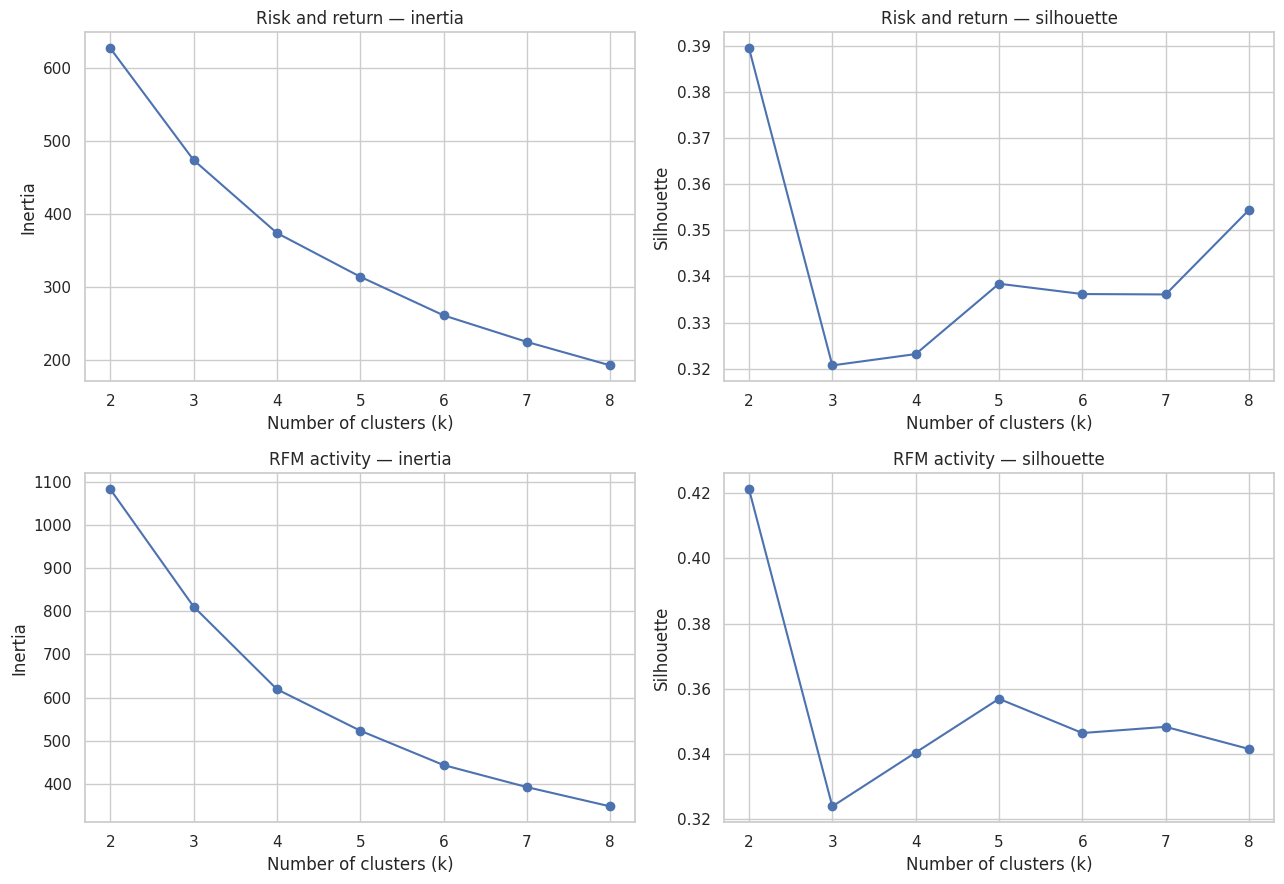

In [14]:
def evaluate_kmeans(X, name):
    rows = []
    labels_by_k = {}
    for k in range(2, 9):
        model = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=50)
        labels = model.fit_predict(X)
        labels_by_k[k] = labels
        sizes = pd.Series(labels).value_counts().sort_index()
        rows.append({"Analysis": name, "k": k, "Silhouette": silhouette_score(X, labels),
                     "Inertia": model.inertia_, "Smallest_Cluster": int(sizes.min()),
                     "Largest_Cluster": int(sizes.max()),
                     "Cluster_Sizes": ", ".join(str(int(v)) for v in sizes.values)})
    return pd.DataFrame(rows), labels_by_k

kmeans_risk_scores, kmeans_risk_labels_by_k = evaluate_kmeans(X_risk, "Risk and return")
kmeans_rfm_scores, kmeans_rfm_labels_by_k = evaluate_kmeans(X_rfm, "RFM activity")
display(kmeans_risk_scores)
display(kmeans_rfm_scores)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, table, title in [
    (axes[0, 0], kmeans_risk_scores, "Risk and return — inertia"),
    (axes[0, 1], kmeans_risk_scores, "Risk and return — silhouette"),
    (axes[1, 0], kmeans_rfm_scores, "RFM activity — inertia"),
    (axes[1, 1], kmeans_rfm_scores, "RFM activity — silhouette"),
]:
    y = "Inertia" if "inertia" in title else "Silhouette"
    ax.plot(table["k"], table[y], marker="o")
    ax.set(title=title, xlabel="Number of clusters (k)", ylabel=y)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kmeans_k_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

### 9.1 Select and fit the two K-means solutions

In [15]:
SELECTED_K_KMEANS_RISK = None
SELECTED_K_KMEANS_RFM = None
k_kmeans_risk = starting_k(kmeans_risk_scores, SELECTED_K_KMEANS_RISK)
k_kmeans_rfm = starting_k(kmeans_rfm_scores, SELECTED_K_KMEANS_RFM)

kmeans_risk_model = KMeans(n_clusters=k_kmeans_risk, random_state=RANDOM_SEED, n_init=50)
kmeans_rfm_model = KMeans(n_clusters=k_kmeans_rfm, random_state=RANDOM_SEED, n_init=50)
kmeans_risk_labels = pd.Series(kmeans_risk_model.fit_predict(X_risk), index=feature_table.index, name="KMeans_Risk_Cluster")
kmeans_rfm_labels = pd.Series(kmeans_rfm_model.fit_predict(X_rfm), index=feature_table.index, name="KMeans_RFM_Cluster")
print("Starting K-means choices:", {"risk_return": k_kmeans_risk, "RFM": k_kmeans_rfm})

Starting K-means choices: {'risk_return': 2, 'RFM': 2}


## 10. Profiles, sector composition, and algorithm comparison

Cluster labels are arbitrary identifiers, so do not compare “cluster 0” across algorithms as if the labels had a shared meaning. Compare the original-unit profiles and use adjusted Rand index (ARI) for membership agreement; ARI is unchanged if cluster numbers are relabelled. Sector composition is reported as within-cluster proportions.

In [16]:
assignments = pd.concat([ward_risk_labels, kmeans_risk_labels, ward_rfm_labels, kmeans_rfm_labels], axis=1)
feature_table = feature_table.join(assignments)

profile_columns = {
    "Risk/return": ["Mean_Weekly_Return", "Weekly_Beta"],
    "RFM": ["R_Recency_Days", "F_High_Volume_Days", "M_Traded_Value_USD"],
}

def cluster_profile(data, label_col, columns):
    means = data.groupby(label_col)[columns].mean().add_prefix("Mean_")
    medians = data.groupby(label_col)[columns].median().add_prefix("Median_")
    sizes = data.groupby(label_col).size().rename("Share_Count")
    return pd.concat([sizes, means, medians], axis=1)

profiles = {
    "Ward_Risk": cluster_profile(feature_table, "Ward_Risk_Cluster", profile_columns["Risk/return"]),
    "KMeans_Risk": cluster_profile(feature_table, "KMeans_Risk_Cluster", profile_columns["Risk/return"]),
    "Ward_RFM": cluster_profile(feature_table, "Ward_RFM_Cluster", profile_columns["RFM"]),
    "KMeans_RFM": cluster_profile(feature_table, "KMeans_RFM_Cluster", profile_columns["RFM"]),
}
for name, table in profiles.items():
    print("\n", name)
    display(table)

ari_comparison = pd.DataFrame([
    {"Feature_Matrix": "Risk and return", "Ward_k": k_ward_risk, "KMeans_k": k_kmeans_risk,
     "Adjusted_Rand_Index": adjusted_rand_score(ward_risk_labels, kmeans_risk_labels)},
    {"Feature_Matrix": "RFM activity", "Ward_k": k_ward_rfm, "KMeans_k": k_kmeans_rfm,
     "Adjusted_Rand_Index": adjusted_rand_score(ward_rfm_labels, kmeans_rfm_labels)},
])
display(ari_comparison)

sector_composition = {}
for label_col in assignments.columns:
    counts = pd.crosstab(feature_table[label_col], feature_table["Sector"])
    proportions = counts.div(counts.sum(axis=1), axis=0)
    sector_composition[label_col] = proportions
    print("\nSector proportions by", label_col)
    display(proportions.round(3))


 Ward_Risk


,Share_Count,Mean_Mean_Weekly_Return,Mean_Weekly_Beta,Median_Mean_Weekly_Return,Median_Weekly_Beta
Ward_Risk_Cluster,,,,,
0,456,0.002416,0.940091,0.002528,0.931461
1,36,0.009021,1.518936,0.008024,1.444517



 KMeans_Risk


,Share_Count,Mean_Mean_Weekly_Return,Mean_Weekly_Beta,Median_Mean_Weekly_Return,Median_Weekly_Beta
KMeans_Risk_Cluster,,,,,
0,147,0.005405,1.368948,0.004938,1.278280
1,345,0.001832,0.817762,0.001921,0.840681



 Ward_RFM


,Share_Count,Mean_R_Recency_Days,Mean_F_High_Volume_Days,Mean_M_Traded_Value_USD,Median_R_Recency_Days,Median_F_High_Volume_Days,Median_M_Traded_Value_USD
Ward_RFM_Cluster,,,,,,,
0,399,12.328321,3.210526,3.835661e+10,11.0,3.0,1.548218e+10
1,93,55.526882,2.075269,4.568673e+10,53.0,2.0,2.084781e+10


... (7 outputs left out)


Sector proportions by Ward_RFM_Cluster


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM_Cluster,,,,,,,,,,,
0,0.043,0.093,0.060,0.048,0.155,0.123,0.175,0.135,0.040,0.075,0.053
1,0.043,0.108,0.086,0.022,0.151,0.097,0.097,0.215,0.086,0.000,0.097



Sector proportions by KMeans_RFM_Cluster


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM_Cluster,,,,,,,,,,,
0,0.045,0.092,0.064,0.047,0.152,0.118,0.175,0.142,0.043,0.071,0.050
1,0.029,0.114,0.071,0.014,0.171,0.114,0.071,0.200,0.086,0.000,0.129


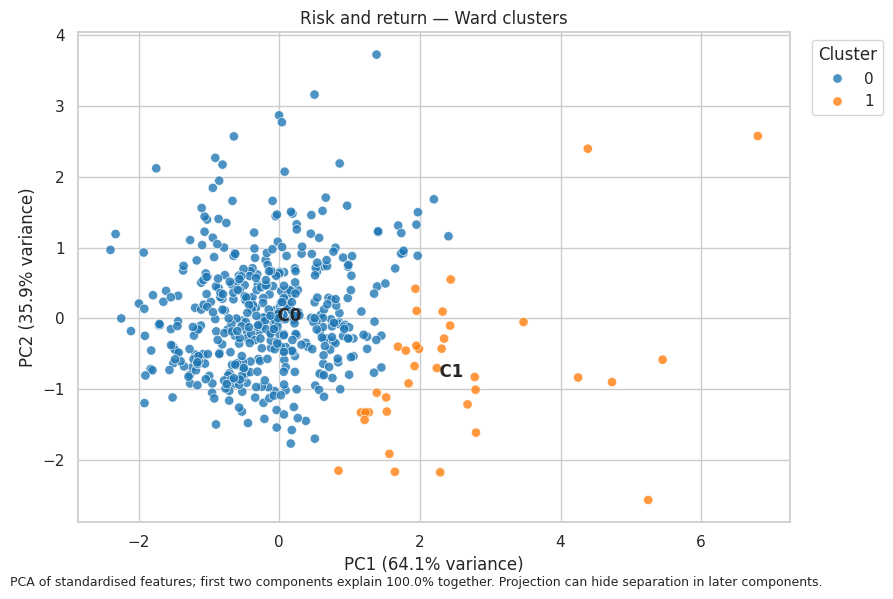

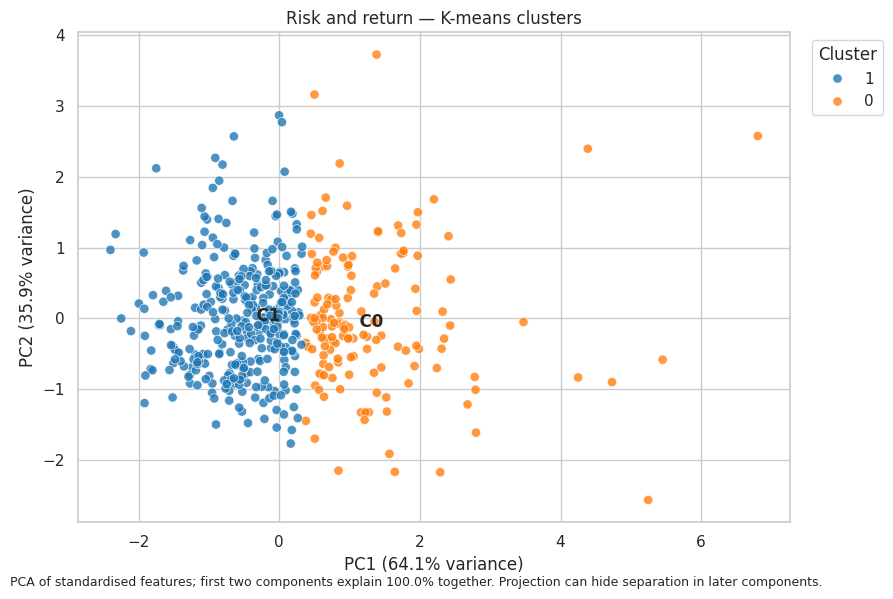

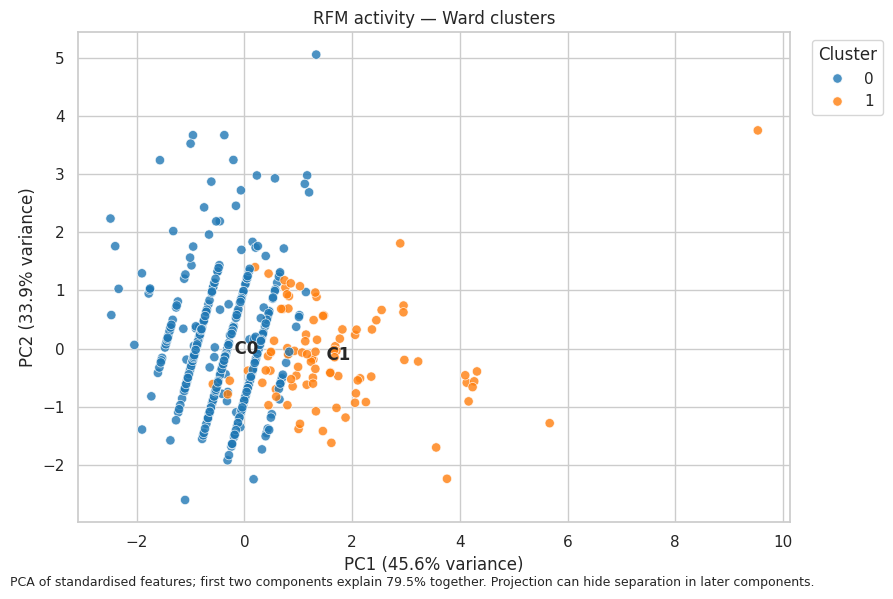

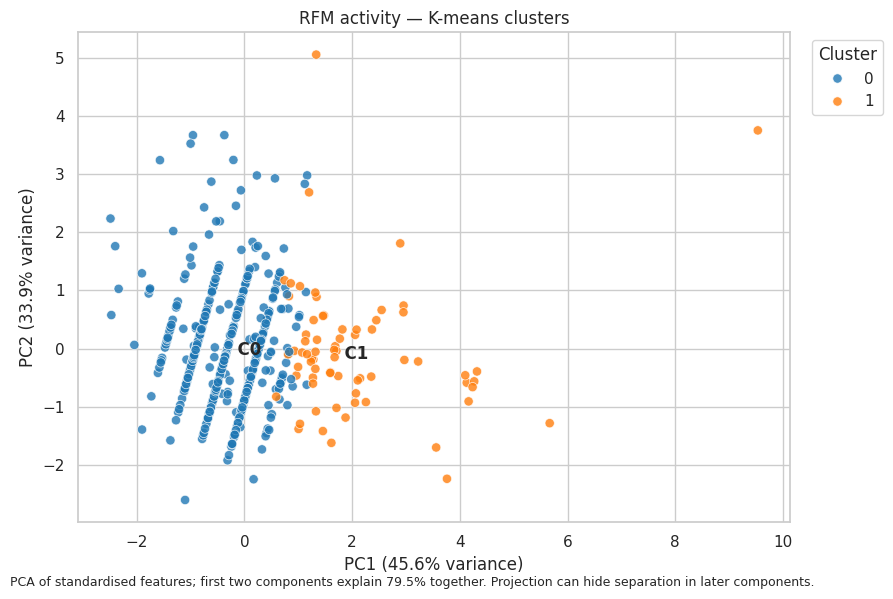

In [17]:
def plot_pca_clusters(X, labels, title, output_name):
    pca = PCA(n_components=2, random_state=RANDOM_SEED)
    coords = pca.fit_transform(X)
    plot_data = pd.DataFrame(coords, index=X.index, columns=["PC1", "PC2"])
    plot_data["Cluster"] = np.asarray(labels).astype(str)
    fig, ax = plt.subplots(figsize=(9, 6))
    sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=45, alpha=.8, ax=ax)
    # Label each projected cluster centre so readers can follow the legend in a dense plot.
    for cluster, group in plot_data.groupby("Cluster"):
        ax.text(group["PC1"].median(), group["PC2"].median(), f"  C{cluster}", weight="bold")
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
    ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.text(.01, .01, f"PCA of standardised features; first two components explain {pca.explained_variance_ratio_.sum():.1%} together. Projection can hide separation in later components.", fontsize=9)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / output_name, dpi=180, bbox_inches="tight")
    plt.show()
    return plot_data

pca_views = {
    "Ward_Risk": plot_pca_clusters(X_risk, ward_risk_labels, "Risk and return — Ward clusters", "pca_ward_risk.png"),
    "KMeans_Risk": plot_pca_clusters(X_risk, kmeans_risk_labels, "Risk and return — K-means clusters", "pca_kmeans_risk.png"),
    "Ward_RFM": plot_pca_clusters(X_rfm, ward_rfm_labels, "RFM activity — Ward clusters", "pca_ward_rfm.png"),
    "KMeans_RFM": plot_pca_clusters(X_rfm, kmeans_rfm_labels, "RFM activity — K-means clusters", "pca_kmeans_rfm.png"),
}

## 11. RFM correlations and Monetary-removal sensitivity

Calculate correlations among `R`, `F`, and `log1p(M)`. Standardisation puts each feature on a comparable scale, but it does not remove correlation: related variables can contribute overlapping information to Euclidean distances. Correlation alone does not prove that one feature dominates.

For the sensitivity comparison, retain the selected Ward RFM cluster count and the same shares. Refit `StandardScaler` using R and F only, fit a new Ward model, compare membership with ARI, and compare traded-value profiles under the resulting reduced-feature groups.

In [18]:
rfm_correlation = feature_table[["R_Recency_Days", "F_High_Volume_Days", "Log1p_M"]].corr(method="pearson")
display(rfm_correlation)

X_rf = feature_table[["R_Recency_Days", "F_High_Volume_Days"]].copy()
rf_scaler = StandardScaler()
X_rf_scaled = pd.DataFrame(rf_scaler.fit_transform(X_rf), index=X_rf.index, columns=X_rf.columns)
ward_rf_model = AgglomerativeClustering(n_clusters=k_ward_rfm, linkage="ward", metric="euclidean")
ward_rf_labels = pd.Series(ward_rf_model.fit_predict(X_rf_scaled), index=feature_table.index, name="Ward_RF_Only_Cluster")

rfm_vs_rf_ari = adjusted_rand_score(ward_rfm_labels, ward_rf_labels)
print("Ward RFM vs Ward R/F-only ARI:", round(rfm_vs_rf_ari, 4))

print("Monetary profiles under the full RFM membership:")
display(feature_table.groupby(ward_rfm_labels)["M_Traded_Value_USD"].agg(Share_Count="size", Mean_USD="mean", Median_USD="median"))
print("Monetary profiles under R/F-only membership:")
display(feature_table.groupby(ward_rf_labels)["M_Traded_Value_USD"].agg(Share_Count="size", Mean_USD="mean", Median_USD="median"))

feature_table["Ward_RF_Only_Cluster"] = ward_rf_labels

,R_Recency_Days,F_High_Volume_Days,Log1p_M
R_Recency_Days,1.000000,-0.338978,0.160878
F_High_Volume_Days,-0.338978,1.000000,0.023238
Log1p_M,0.160878,0.023238,1.000000


Ward RFM vs Ward R/F-only ARI: 0.9525
Monetary profiles under the full RFM membership:


,Share_Count,Mean_USD,Median_USD
Ward_RFM_Cluster,,,
0,399,3.835661e+10,1.548218e+10
1,93,4.568673e+10,2.084781e+10


Monetary profiles under R/F-only membership:


,Share_Count,Mean_USD,Median_USD
Ward_RF_Only_Cluster,,,
0,400,3.782930e+10,1.546039e+10
1,92,4.805905e+10,2.095020e+10


## 12. Inclusion/exclusion log, exports, and run record

This final section writes the share-level feature table, all four baseline assignments, the R/F-only sensitivity assignment, ticker selection and validation details, model-selection diagnostics, and an analysis record. Keep these with the notebook in the public repository. Review the file sizes and your module's data-sharing requirements before publishing the market-data snapshot.

In [19]:
# Combine validation and weekly-feature screens into one row per share.
exclusion_log = validation.join(
    risk_features_all[["Paired_Weekly_Observations", "Weekly_Coverage", "Risk_Screen_Reason"]],
    how="left",
).join(rfm_all[["R_Recency_Days", "F_High_Volume_Days", "M_Traded_Value_USD", "RFM_Screen_Reason"]], how="left")
exclusion_log["Final_Common_Analysis_Set"] = exclusion_log.index.isin(feature_table.index)
exclusion_log["Final_Reason"] = np.where(
    exclusion_log["Final_Common_Analysis_Set"], "included in all four baseline models",
    np.where(exclusion_log["Daily_Coverage"].lt(MIN_DAILY_COVERAGE), "failed daily coverage screen",
    np.where(exclusion_log["Risk_Screen_Reason"].ne("included in risk screen"), "failed weekly risk/return screen",
    np.where(exclusion_log["RFM_Screen_Reason"].ne("included in RFM screen"), "missing RFM feature or insufficient history", "not in common analysis set")))
)

feature_table.to_csv(OUTPUT_DIR / "feature_table_and_cluster_assignments.csv")
exclusion_log.to_csv(OUTPUT_DIR / "inclusion_exclusion_log.csv")
weekly_returns_all.to_csv(OUTPUT_DIR / "weekly_adjusted_returns.csv")
risk_features_all.to_csv(OUTPUT_DIR / "weekly_return_beta_features_all_shares.csv")
rfm_all.to_csv(OUTPUT_DIR / "daily_rfm_features_all_shares.csv")
ward_risk_scores.to_csv(OUTPUT_DIR / "ward_risk_k_comparison.csv", index=False)
ward_rfm_scores.to_csv(OUTPUT_DIR / "ward_rfm_k_comparison.csv", index=False)
kmeans_risk_scores.to_csv(OUTPUT_DIR / "kmeans_risk_k_comparison.csv", index=False)
kmeans_rfm_scores.to_csv(OUTPUT_DIR / "kmeans_rfm_k_comparison.csv", index=False)
rfm_correlation.to_csv(OUTPUT_DIR / "rfm_correlations.csv")
ari_comparison.to_csv(OUTPUT_DIR / "algorithm_ari_comparison.csv", index=False)

for name, table in profiles.items():
    table.to_csv(OUTPUT_DIR / f"profile_{name.lower()}.csv")
for name, table in sector_composition.items():
    table.to_csv(OUTPUT_DIR / f"sector_composition_{name.lower()}.csv")

run_record = {
    "ticker_source": wiki_url,
    "ticker_retrieved_at_utc": retrieved_at_utc,
    "price_source": "Yahoo Finance via yfinance",
    "benchmark": BENCHMARK,
    "study_start_inclusive": str(STUDY_START.date()),
    "study_end_exclusive": str(STUDY_END.date()),
    "download_start_with_warmup": str(DOWNLOAD_START.date()),
    "observation_date": str(OBSERVATION_DATE.date()),
    "daily_coverage_rule": MIN_DAILY_COVERAGE,
    "weekly_coverage_rule": MIN_WEEKLY_COVERAGE,
    "minimum_paired_weekly_observations": MIN_PAIRED_WEEKS,
    "duplicate_dates_removed": duplicate_date_count,
    "common_share_count": len(feature_table),
    "selected_k": {"Ward_risk": k_ward_risk, "Ward_RFM": k_ward_rfm,
                   "KMeans_risk": k_kmeans_risk, "KMeans_RFM": k_kmeans_rfm,
                   "Ward_RF_only_sensitivity": k_ward_rfm},
    "random_seed": RANDOM_SEED,
    "versions": versions,
}
with open(OUTPUT_DIR / "run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(run_record, f, indent=2)

print("Saved outputs to:", OUTPUT_DIR.resolve())
print("Files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {path.name} ({path.stat().st_size:,} bytes)")
display(feature_table.head())

Saved outputs to: /content/coursework_outputs
Files:
- algorithm_ari_comparison.csv (127 bytes)
- daily_prices_snapshot.csv.gz (10,240,535 bytes)
- daily_rfm_features_all_shares.csv (24,971 bytes)
- feature_table_and_cluster_assignments.csv (99,330 bytes)
- inclusion_exclusion_log.csv (119,643 bytes)
- kmeans_k_diagnostics.png (212,810 bytes)
- kmeans_rfm_k_comparison.csv (652 bytes)
- kmeans_risk_k_comparison.csv (674 bytes)
- pca_kmeans_rfm.png (192,400 bytes)
- pca_kmeans_risk.png (236,098 bytes)
- pca_ward_rfm.png (190,150 bytes)
- pca_ward_risk.png (239,644 bytes)
- profile_kmeans_rfm.csv (352 bytes)
- profile_kmeans_risk.csv (293 bytes)
- profile_ward_rfm.csv (349 bytes)
- profile_ward_risk.csv (286 bytes)
- rfm_correlations.csv (221 bytes)
- run_metadata.json (896 bytes)
- sector_composition_kmeans_rfm_cluster.csv (592 bytes)
- sector_composition_kmeans_risk_cluster.csv (627 bytes)
- sector_composition_ward_rfm_cluster.csv (607 bytes)
- sector_composition_ward_risk_cluster.csv (

,Mean_Weekly_Return,Weekly_Beta,Paired_Weekly_Observations,Weekly_Coverage,Daily_Coverage,Sector,Symbol,Security,Risk_Screen_Reason,R_Recency_Days,F_High_Volume_Days,M_Traded_Value_USD,RFM_Screen_Reason,Log1p_M,Observation_Date,Ward_Risk_Cluster,KMeans_Risk_Cluster,Ward_RFM_Cluster,KMeans_RFM_Cluster,Ward_RF_Only_Cluster
YahooSymbol,,,,,,,,,,,,,,,,,,,,
MMM,0.001142,0.869079,207,1.0,1.0,Industrials,MMM,3M,included in risk screen,11,4,2.599146e+10,included in RFM screen,23.981034,2024-12-31,0,1,0,0,0
AOS,0.001991,1.042804,207,1.0,1.0,Industrials,AOS,A. O. Smith,included in risk screen,11,2,4.748980e+09,included in RFM screen,22.281196,2024-12-31,0,1,0,0,0
ABT,0.000971,0.583544,207,1.0,1.0,Health Care,ABT,Abbott Laboratories,included in risk screen,11,1,3.523027e+10,included in RFM screen,24.285172,2024-12-31,0,1,0,0,0
ABBV,0.003749,0.425366,207,1.0,1.0,Health Care,ABBV,AbbVie,included in risk screen,11,3,6.837054e+10,included in RFM screen,24.948208,2024-12-31,0,1,0,0,0
ACN,0.002376,1.143299,207,1.0,1.0,Information Technology,ACN,Accenture,included in risk screen,11,2,5.199430e+10,included in RFM screen,24.674400,2024-12-31,0,1,0,0,0
